# Retrieval Preparation
**ResolveX - M4: Evidence preparation and initial search experiments**

Prepare Ask Ubuntu cases and test BM25 (keyword search) and a small dense retrieval pilot (embedding search). The comparison and held-out evaluation follow in Sections 7–10.

## 1. Load the prepared data

Reuse the M2 knowledge base and full duplicate links. Keep generated data, indexes and models locally under `data/processed/`.

In [1]:
from contextlib import closing
from pathlib import Path
import json
import sqlite3
import sys
import time

import pandas as pd
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents)
             if (p / "src/retrieval.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook within ResolveX")
sys.path.insert(0, str(ROOT))
from src.retrieval import (policy_review_sample, prepare_evidence, build_benchmark,
                           development_queries, build_bm25, evaluate_retrieval,
                           build_dense_pilot, file_hash)
print("Source: M2 knowledge_base.jsonl and full duplicate_relationships.csv")

Source: M2 knowledge_base.jsonl and full duplicate_relationships.csv


## 2. Review the answer-selection policy

Select one answer per question:

- Use the valid accepted answer if its score is zero or higher.
- Otherwise, use the highest positive-score answer; break ties by smallest answer ID.
- Exclude questions with no qualifying answer. Preserve the M2 data.

Read two examples from each of five policy groups, using development groups and seed 42. This AI-assisted review checks the rule, not technical correctness.

In [2]:
review = pd.DataFrame(policy_review_sample(ROOT))
display(review[["QuestionId", "Bucket", "Title", "InspectedAnswerId", "AnswerScore", "Selection", "SelectedAnswerId"]])
# Full text is available in review["QuestionText"] and review["AnswerText"].
print("Reviewed examples:", len(review))

,QuestionId,Bucket,Title,InspectedAnswerId,AnswerScore,Selection,SelectedAnswerId
0,369099,accepted_negative,Unable to download Ubuntu SDK,369107,-1,no_supported_answer,None
1,425018,accepted_negative,Log Out problem after upgrading from 13.04 to ...,425172,-1,no_supported_answer,None
2,94902,accepted_positive,How can I switch between keyboard layouts by p...,94910,56,accepted,94910
3,961991,accepted_positive,How shall I install and invoke IDLE for Python3?,961994,6,accepted,961994
4,500966,accepted_zero,Shell script to run VM,500970,0,accepted,500970
5,183885,accepted_zero,"Can't install Ubuntu on HP Series 2000, blank ...",183892,0,accepted,183892
6,567454,no_supported_answer,Install Ubuntu 14.04 alongside Windows 8 Problem,568458,0,no_supported_answer,None
7,251074,no_supported_answer,Uninstall Ubuntu 12.10 and revert back to Wind...,251076,0,no_supported_answer,None
8,44566,positive_fallback,Enable wifi on my computer - firmware missing,44574,1,positive_fallback,44574
9,258521,positive_fallback,Unable to install VirtualBox on Ubuntu 12.10: ...,260945,10,positive_fallback,260945


Reviewed examples: 10


### Review findings

The full questions and inspected answers were read for all ten examples.

| Question IDs | Finding |
| --- | --- |
| 94902, 961991 | Positive accepted answers address the requests, with version-specific instructions. |
| 500966, 183885 | Zero-score accepted answers qualify, but include VM state changes and old Ubuntu advice. |
| 369099, 425018 | Negative accepted answers are excluded: lock-removal commands and a plausible historical fix. Filtering may discard useful advice. |
| 44566, 258521 | Positive fallbacks offer troubleshooting steps; the first provides device discovery rather than a confirmed firmware fix. |
| 567454, 251074 | No accepted or positive-score answer qualifies. |

Acceptance and votes do not guarantee solved cases, safe instructions or current applicability.

## 3. Prepare the retrieval data

Use SQLite, a local database file, to store selected cases and their IDs, dates, scores, tags, links, licenses and author details. Resolve names from `Users.xml`, then available post display names; leave unavailable names missing.

Create chunks of about 180 words. Preserve all characters through stored offsets and keep code blocks whole, including oversized blocks. Smaller embedding windows do not change the saved text.

In [3]:
db_path, corpus = prepare_evidence(ROOT)
db_path = Path(db_path).resolve(strict=True)
print("Database:", db_path)

with closing(sqlite3.connect(db_path.as_uri() + "?mode=ro", uri=True)) as connection:
    assert connection.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
    assert connection.execute("SELECT count(*) FROM cases").fetchone()[0] == corpus["counts"]["cases"]
    assert connection.execute("SELECT count(*) FROM chunks u LEFT JOIN cases c USING(question_id) WHERE c.question_id IS NULL").fetchone()[0] == 0
    author_preview = pd.read_sql_query("""
        SELECT c.question_id,c.answer_id,c.selection,
               COALESCE(qa.name,qp.name) AS question_author,
               COALESCE(aa.name,ap.name) AS answer_author
        FROM cases c LEFT JOIN authors qa ON c.question_owner=qa.owner_id
        LEFT JOIN authors aa ON c.answer_owner=aa.owner_id
        LEFT JOIN post_authors qp ON c.question_id=qp.post_id
        LEFT JOIN post_authors ap ON c.answer_id=ap.post_id
        ORDER BY c.question_id LIMIT 5
    """, connection)

display(pd.Series(corpus["counts"], name="Count").to_frame())
display(author_preview)
print("Corpus fingerprint:", corpus["fingerprint"])
print("Database checks passed.")

Database: C:\Users\jc\Desktop\ResolveX\data\processed\retrieval\evidence.sqlite


,Count
source_questions,318537
accepted,135482
chunks,618330
oversized_code_chunks,15509
cases,240555
positive_fallback,105073
no_supported_answer,77982
question_user_name,234932
question_post_name,5622
question_unavailable_name,1


,question_id,answer_id,selection,question_author,answer_author
0,1,2,accepted,Nathan Osman,txwikinger
1,100,137,accepted,David Siegel,MarkovCh1
2,1000006,1000556,accepted,Jonathan Holvey,Jonathan Holvey
3,1000009,1000203,accepted,Jamie Hutber,egmont
4,1000012,1000018,accepted,Manos Kounelakis,Sadegh Ghasemi


Corpus fingerprint: b3334850751bb6d7244789378c59329249f60478c4f5ce6a12ea67fd9b6e77c5
Database checks passed.


## 4. Prepare the retrieval benchmark

Use recorded duplicate targets as known relevant results. Build connected groups from all duplicate links, then split groups 80/20 into development and held-out sets with seed 42. Row proportions depend on group sizes. Keep available targets and report exclusions.

Queries use title and body. Exclude direct target links and duplicate notices, then remove remaining Ask Ubuntu post URLs. Filtering may remove useful questions too.

Exclude all results belonging to the query question and count each retrieved question once. Duplicate links are incomplete relevance labels; they do not verify answer correctness.

In [4]:
benchmark = build_benchmark(ROOT, db_path, corpus["fingerprint"])
display(pd.Series(benchmark["counts"], name="Count").to_frame())
queries = development_queries(db_path, limit=100, seed=42)
assert len(queries) == 100
assert len({q["group_id"] for q in queries}) == len(queries)
assert all(q["split"] == "development" for q in queries)
print("Development sample:", len(queries), "queries from distinct groups")
print("Saved assignments:", (db_path.parent / "query_assignments.csv").relative_to(ROOT))
print("Held-out retrieval queries scored: 0")

,Count
source_pairs,41931
unavailable_target_pairs,593
queries_with_available_targets,37066
direct_target_link_queries,5379
development_queries,28721
eligible_pairs,35654
heldout_queries,2924
duplicate_notice_queries,42
development_groups,6816
heldout_groups,1689


Development sample: 100 queries from distinct groups
Saved assignments: data\processed\retrieval\query_assignments.csv
Held-out retrieval queries scored: 0


## 5. Test keyword search with BM25

Index each case's title, question and selected answer. Preserve terms such as `apt-get`, `etc/fstab`, versions and IP addresses.

Start with k1=1.2, b=0.75 and positive log IDF. Evaluate 100 development queries from distinct groups using Recall@1/5/10 and MRR@10.

Reference: [BM25 settings](https://lucene.apache.org/core/9_12_1/core/org/apache/lucene/search/similarities/BM25Similarity.html).

In [5]:
started = time.perf_counter()
bm25 = build_bm25(db_path, corpus["fingerprint"])
bm25_build_seconds = time.perf_counter() - started
started = time.perf_counter()
bm25_rows = pd.DataFrame(evaluate_retrieval(queries, bm25.search))
bm25_seconds = time.perf_counter() - started
bm25_metrics = bm25_rows[["Recall@1", "Recall@5", "Recall@10", "MRR@10"]].mean()
display(bm25_metrics.to_frame("BM25 development"))
print("Indexed cases:", len(bm25.question_ids))
print("Vocabulary:", len(bm25.vectorizer.vocabulary_))
print("Build/load seconds:", round(bm25_build_seconds, 2))
print("Mean query milliseconds:", round(1000 * bm25_seconds / len(queries), 2))
print("Index bytes:", (db_path.parent / "bm25.joblib").stat().st_size)
print("Held-out retrieval queries scored: 0")

,BM25 development
Recall@1,0.055000
Recall@5,0.195000
Recall@10,0.240000
MRR@10,0.119813


Indexed cases: 240555
Vocabulary: 1531729
Build/load seconds: 12.51
Mean query milliseconds: 52.29
Index bytes: 193105582
Held-out retrieval queries scored: 0


## 6. Test embedding search on a small sample

Use pretrained `all-MiniLM-L6-v2` on CPU, with a fixed revision, and FAISS for exact cosine search over normalized vectors. No fine-tuning.

Randomly select 2,000 cases with seed 42, independently of relevance. Use overlapping embedding windows within 256 tokens, preserving stored code. Rank questions by their best window and exclude every window of the query itself.

Evaluate up to 100 development queries with targets in this sample. **Different candidate sets and queries prevent direct comparison with BM25.** The next comparison needs shared data.

Model: [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2).

In [6]:
import torch
import faiss
from sentence_transformers import SentenceTransformer

torch.set_num_threads(4)
faiss.omp_set_num_threads(4)
MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"
MODEL_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
model = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION,
    cache_folder=str(ROOT / "data/processed/embedding_cache"), device="cpu", local_files_only=True)
started = time.perf_counter()
dense, pilot = build_dense_pilot(db_path, corpus["fingerprint"], model, MODEL_ID, MODEL_REVISION,
                                limit=2000, seed=42)
pilot_build_seconds = time.perf_counter() - started
pilot_queries = development_queries(db_path, limit=100, seed=42, candidate_ids=pilot["candidate_ids"])
assert pilot_queries and all(q["split"] == "development" for q in pilot_queries)
started = time.perf_counter()
dense_rows = pd.DataFrame(evaluate_retrieval(pilot_queries, dense.search))
dense_seconds = time.perf_counter() - started
dense_metrics = dense_rows[["Recall@1", "Recall@5", "Recall@10", "MRR@10"]].mean()
display(dense_metrics.to_frame("Dense pilot development"))
print("Pilot cases:", pilot["cases"], "/", corpus["counts"]["cases"])
print("Embedding views:", pilot["embedding_views"], "dimensions:", pilot["dimension"])
print("Model token limit:", model.max_seq_length)
print("Pilot development queries:", len(pilot_queries))
print("Build/load seconds:", round(pilot_build_seconds, 2))
print("Mean query milliseconds:", round(1000 * dense_seconds / len(pilot_queries), 2))
print("Index bytes:", pilot["index_bytes"])
print("Held-out retrieval queries scored: 0")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,Dense pilot development
Recall@1,0.821429
Recall@5,0.928571
Recall@10,0.928571
MRR@10,0.872024


Pilot cases: 2000 / 240555
Embedding views: 7725 dimensions: 384
Model token limit: 256
Pilot development queries: 56
Build/load seconds: 0.07
Mean query milliseconds: 73.98
Index bytes: 11865645
Held-out retrieval queries scored: 0


## Findings and next steps

- **240,555 cases:** 135,482 accepted answers and 105,073 positive fallbacks; 77,982 questions excluded.
- **618,330 chunks**, including 15,509 oversized code chunks preserved whole. One question and one selected answer have unavailable author names.
- **28,721 development / 2,924 held-out queries.** Duplicate groups stay separate; no identical normalized query text crosses sets.

| Experiment | Candidate cases | Development queries | Recall@10 | MRR@10 |
| --- | ---: | ---: | ---: | ---: |
| BM25 | 240,555 | 100 | 0.2400 | 0.1198 |
| Dense pilot | 2,000 | 56 | 0.9286 | 0.8720 |

BM25 Recall@1 is **0.0550** and Recall@5 is **0.1950**. It misses many known targets. The dense pilot uses 7,725 windows with 384 dimensions. Its results use a smaller corpus and different queries, so they do not show whether it outperforms BM25.

Next: choose a shared corpus and queries that fit available resources, compare BM25/dense/hybrid, and inspect failures, source age and weak evidence. Then freeze settings, evaluate held-out queries and finish the reusable retrieval function.

# Retrieval Comparison and Evaluation

Continue the experiments above using a shared corpus, then evaluate the selected retriever.

## 7. Compare retrieval methods

Use the same 5,000 randomly sampled cases for BM25, MiniLM and hybrid search (seed 42). Hybrid search combines ranked results using reciprocal rank fusion, with dense weights of 0.25, 0.50 and 0.75.

Sample up to 200 queries from distinct groups per split, keeping queries with an available known target. This gives 145 development and 44 held-out queries. Scores apply to this smaller corpus.

Select the highest development MRR@10 among methods averaging at most one second per query, with Recall@10 as the tie-breaker. Save the indexes for reuse.


,eligible_queries,eligible_groups,sampled_queries,benchmark_queries
development,689,145,145,28721
heldout,71,44,44,2924


Candidate cases: 5000 / 240555


C:\Users\jc\Desktop\ResolveX\src\retrieval.py:699: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  index = faiss.IndexFlatIP(model.get_sentence_embedding_dimension())


Dense cases: 1000/5000
Dense cases: 2000/5000
Dense cases: 3000/5000
Dense cases: 4000/5000
Dense cases: 5000/5000


,Index details
cases,5.000000e+03
embedding_views,1.959000e+04
dimensions,3.840000e+02
bm25_build_seconds,2.948672e+00
dense_build_seconds,6.974516e+02
index_bytes,3.468294e+07


,queries,mean_query_ms,Recall@1,Recall@5,Recall@10,MRR@10
method,,,,,,
bm25,145,2.4010,0.3724,0.5448,0.5862,0.4407
dense,145,86.7532,0.6828,0.8759,0.9103,0.7577
hybrid_0.25,145,89.2886,0.4414,0.6207,0.7310,0.5252
hybrid_0.50,145,89.2632,0.5034,0.7103,0.8069,0.5931
hybrid_0.75,145,89.2559,0.5724,0.7724,0.8690,0.6589


Selected method: dense


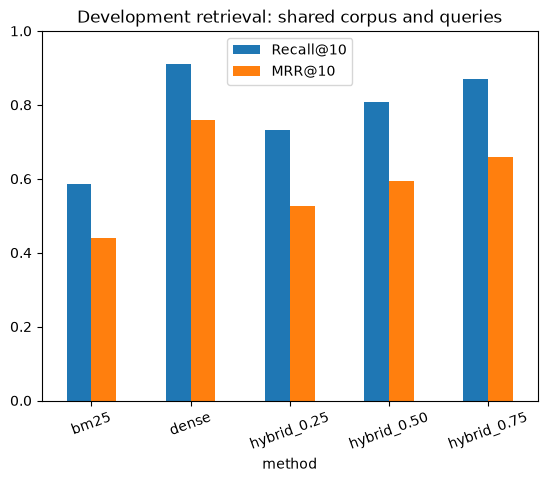

In [7]:
from src.retrieval import (
    prepare_comparison, comparison_queries, build_comparison_indexes,
    compare_retrievers, freeze_retriever, load_retriever,
    retrieval_diagnostics, evaluate_heldout,
)

scope = prepare_comparison(db_path, corpus["fingerprint"], case_limit=5000, query_limit=200, seed=42)
display(pd.DataFrame(scope["coverage"]).T)
print("Candidate cases:", len(scope["candidate_ids"]), "/", scope["total_cases"])
indexes = build_comparison_indexes(db_path, scope, model)
display(pd.Series({k: v for k, v in indexes["manifest"].items() if k not in ["signature", "files"]}).to_frame("Index details"))
development = compare_retrievers(db_path, scope, indexes)
comparison = pd.DataFrame(development["summary"]).set_index("method")
display(comparison.round(4))
comparison[["Recall@10", "MRR@10"]].plot.bar(rot=20, ylim=(0, 1), title="Development retrieval: shared corpus and queries")
print("Selected method:", development["selected_method"])


## 8. Inspect evidence quality

Flag weak evidence when the top score or relative score margin falls in the bottom tenth of development values. This is a simple warning, not calibrated confidence.

Inspect answer age and examples whose first result is not a recorded target. Missing duplicate links can make useful results appear incorrect, and older advice may still be relevant.


,Queries,KnownTargetAt1
WeakEvidence,,
False,120,0.766667
True,25,0.280000


,Retrieved answer age (years)
count,725.000000
mean,10.880147
std,3.302627
min,2.759754
25%,8.468172
50%,11.299110
75%,13.511294
max,16.194387


,QueryId,QueryTitle,RetrievedTitle,KnownTargets,WeakEvidence
0,1014511,Is there an Ubuntu equivalent of Microsoft Access 2010?,Database for Ubuntu compatible with Microsoft Database?,[187389],False
1,831280,brightness not working ubuntu 16.04 LTS,"Brightness problem on Ubuntu 20.04 (System panel works, but nothing change)",[476664],False
2,1404869,"Unable to correct problems, you have held broken packages when trying to install PHP",Updating Ubuntu & understanding errors thrown by APT,[1403619],True
3,1060771,Wine installation issues,Error messages when installig wine,[866901],False
4,1013955,How remove or reset mysql password!,Which is the easiest way to reset the mysql root password?,[118772],False
5,988519,How do I delete Windows files from Ubuntu?,"Strange errors, including all files are read-only",[626353],False
6,932794,Removing Ubuntu from dual boot,How to completely remove Ubuntu?,[83403],False
7,547693,Ubuntu 14.10 Auto Login,How to disable password after login to 14.04?,[11240],False
8,1418177,UBUNTU - WIFI not working - hp pavilion aero laptop 13-be0008ur,"Wifi on my laptop drops after just less than a minute, while the network manager still says ""connected""",[1390106],False
9,908056,Ubuntu 16.04 Server Fresh Install - Can't ping gateway & no wifi network at all,No ethernet on Ubuntu 14.04 LTS,[271378],False



Question: Is there an Ubuntu equivalent of Microsoft Access 2010?

I have a relational database Access 2010 which I would like to run with an Ubuntu programme. Is this possible?
Retrieved answer: I assume that you mean Microsoft Access as the database.



Easiest alternative to use on Ubuntu is LibreOffice Base. Your system probably already has LibreOffice, but you will probably have to add Base:



```
sudo apt-get install libreoffice-base

```



Once installed, you should be able to open your Access file, but your mileage may vary, see here: Is it possible to open an Access 2010 database file without using Wine or VirtualBox? (https://askubuntu.com/questions/187389/is-it-possible-to-open-a-office-2010-access-files)
Source: https://askubuntu.com/a/371764

Question: brightness not working ubuntu 16.04 LTS

I've a Sumsung series 5 laptop with 4GB ram dual booted with Windows 10 and Ubuntu 16.04 LTS. My brightness does not work although the "function key+brightness button" shows the in

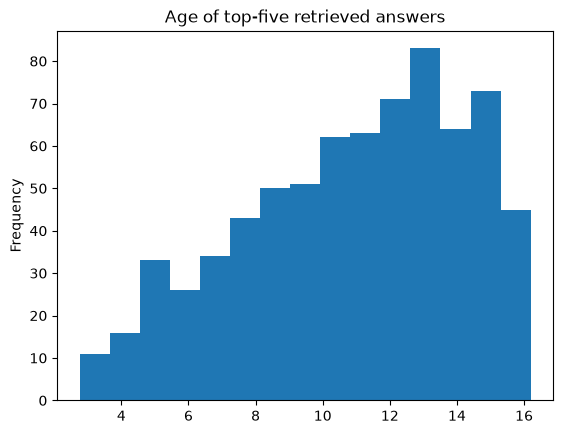

In [8]:
config = freeze_retriever(db_path, scope, indexes, development, review_quantile=0.10)
retriever = load_retriever(ROOT, model=model)
dev_queries = comparison_queries(db_path, scope)
diagnostics = retrieval_diagnostics(
    retriever, dev_queries, development["records"][config["method"]],
    as_of=pd.Timestamp.now(tz="UTC").date().isoformat(),
)
warnings = pd.DataFrame(diagnostics["warnings"])
ages = pd.DataFrame(diagnostics["source_ages"])
display(warnings.groupby("WeakEvidence").agg(Queries=("QueryId", "size"), KnownTargetAt1=("KnownTargetAt1", "mean")))
if not ages.empty:
    display(ages["AgeYears"].describe().to_frame("Retrieved answer age (years)"))
    ages["AgeYears"].plot.hist(bins=15, title="Age of top-five retrieved answers")
failures = pd.DataFrame(diagnostics["failures"])
if not failures.empty:
    with pd.option_context("display.max_colwidth", 120):
        display(failures[["QueryId", "QueryTitle", "RetrievedTitle", "KnownTargets", "WeakEvidence"]])
    for row in diagnostics["failures"][:3]:
        print("\nQuestion:", row["QueryText"])
        print("Retrieved answer:", row["AnswerText"])
        print("Source:", row["Sources"]["answer"]["source_url"])
else:
    print("Every sampled development query retrieved a known target first.")


## 9. Try ticket-like requests

Inspect clear, ambiguous and unsupported requests. These examples illustrate behavior; they are not a labeled ticket benchmark. Check relevance, Ubuntu version compatibility and source attribution before using any advice.

In [9]:
examples = [
    ("Network", "Wi-Fi keeps disconnecting", "My Ubuntu laptop disconnects every few minutes while other devices stay connected."),
    ("Packages", "Cannot install software", "apt reports unmet dependencies and dpkg returns an error."),
    ("Storage", "Cannot mount my external disk", "Ubuntu reports an NTFS filesystem error."),
    ("Ambiguous", "Ubuntu no longer boots", "After resizing partitions and updating the kernel, GRUB cannot find the root filesystem."),
    ("Unsupported", "Payroll reimbursement missing", "My approved travel claim has not been paid."),
]
ticket_rows = []
for scenario, title, body in examples:
    result = retriever.retrieve(title, body, k=3)
    for hit in result["evidence"]:
        ticket_rows.append({"Scenario": scenario, "Ticket": title, "Rank": hit["rank"],
                           "RetrievedTitle": hit["title"], "Score": hit["score"],
                           "WeakEvidence": result["weak_evidence"],
                           "Source": hit["sources"]["answer"]["source_url"],
                           "Author": hit["sources"]["answer"]["author_name"]})
with pd.option_context("display.max_colwidth", 100):
    display(pd.DataFrame(ticket_rows))
print("Frozen method:", config["method"])
print("Weak-evidence policy:", config["weak_evidence"])


,Scenario,Ticket,Rank,RetrievedTitle,Score,WeakEvidence,Source,Author
0,Network,Wi-Fi keeps disconnecting,1,Ubuntu Wifi keeps reconnecting even after router reconfiguring,0.701683,False,https://askubuntu.com/a/1272915,kannzzmm2
1,Network,Wi-Fi keeps disconnecting,2,WiFi disconnects for few seconds and resumes,0.670051,False,https://askubuntu.com/a/734963,GAD3R
2,Network,Wi-Fi keeps disconnecting,3,How do I avoid random Wireless LAN disconnects?,0.615109,False,https://askubuntu.com/a/236944,leorize
3,Packages,Cannot install software,1,"""Unmet Dependencies"" problem when trying apt-get install",0.674551,False,https://askubuntu.com/a/245276,Eliah Kagan
4,Packages,Cannot install software,2,Unable to resolve unmet dependencies,0.649063,False,https://askubuntu.com/a/1452235,user535733
5,Packages,Cannot install software,3,Error when trying to install mysql server,0.600897,False,https://askubuntu.com/a/891222,yurtesen
6,Storage,Cannot mount my external disk,1,Mounting of external Harddrive,0.683863,False,https://askubuntu.com/a/245453,Mazeryt
7,Storage,Cannot mount my external disk,2,Unable to mount internal hard drive,0.677034,False,https://askubuntu.com/a/378698,Avinash Raj
8,Storage,Cannot mount my external disk,3,"External HDD fails to mount ""exit status 13: `$MFTMirr does not match $MFT (record 0)""",0.676846,False,https://askubuntu.com/a/945009,heynnema
9,Ambiguous,Ubuntu no longer boots,1,Ubuntu doesn't boot after kernel update,0.598822,False,https://askubuntu.com/a/36472,s3v3n


Frozen method: dense
Weak-evidence policy: {'score_floor': 0.5767111659049988, 'margin_floor': 0.008273645188483796}


## 10. Evaluate the frozen retriever

Evaluate only the selected method on the held-out query sample. Settings were selected using development results. Repeated runs load the saved report; these results are not used to change the method or warning thresholds.

In [10]:
heldout = evaluate_heldout(retriever, scope)
final_metrics = pd.DataFrame([{
    "Method": heldout["method"], "CandidateCases": heldout["candidate_cases"],
    "HeldOutQueries": heldout["queries"], **heldout["metrics"],
}]).rename(columns={"milliseconds": "MeanQueryMs", "WeakEvidence": "WeakEvidenceRate"})
display(final_metrics.round(4))
print("Saved artifacts:", (db_path.parent / "comparison").relative_to(ROOT))


,Method,CandidateCases,HeldOutQueries,Recall@1,Recall@5,Recall@10,MRR@10,MeanQueryMs,WeakEvidenceRate
0,dense,5000,44,0.6364,0.8409,0.8864,0.7188,60.0287,0.2045


Saved artifacts: data\processed\retrieval\comparison


## Results and limitations

**Results**

- On the shared 5,000-case corpus and 145 development queries, MiniLM has the highest MRR@10: **0.7577**, compared with **0.4407** for BM25 and **0.6589** for the best tested hybrid setting.
- On **44 held-out queries**, the selected dense retriever achieves Recall@1 **0.6364**, Recall@5 **0.8409**, Recall@10 **0.8864** and MRR@10 **0.7188**. Mean search time is about **60 ms** per query.
- The weak-evidence flag is raised for **20.45%** of held-out queries. On development queries, a known target is ranked first for **76.67%** of unflagged queries and **28.00%** of flagged queries.
- Retrieved development answers have a median age of **11.3 years**, counting the top five results per query. Version compatibility needs review.

**Example review**

- The Access question retrieves a relevant LibreOffice Base answer that links to the recorded target. A missing exact target does not always mean the retrieved answer is useless.
- The brightness question concerns Ubuntu 16.04, while the retrieved case concerns Ubuntu 20.04. Similar symptoms do not establish that the same fix applies.
- The Wi-Fi, package and disk examples retrieve related cases. The ambiguous boot example receives no weak-evidence flag; its cause still needs investigation.
- The unsupported payroll example retrieves unrelated Ubuntu cases and receives a weak-evidence flag. One example does not establish reliable detection of unsupported requests.

**Limitations**

- Evaluation uses a sampled corpus and only 44 held-out queries with available targets. These scores do not establish full-corpus or real-ticket performance.
- Recorded duplicate targets provide incomplete relevance labels. Accepted answers and positive scores do not verify technical correctness.
- The weak-evidence flag can miss unsuitable advice. Engineers must review the sources and Ubuntu versions before acting.

`load_retriever(ROOT)` loads the saved indexes and policy. `retrieve(title, body)` returns ranked cases, technical text, source attribution and a weak-evidence flag. Generated artifacts stay local. M5 will integrate retrieval into the technical support agent.
